# Causal vs Full Attention — Interactive Research Notebook

**A controlled Transformer ablation** · Pretrained small checkpoints included · CPU friendly.

This is a reproducible, **synthetic** information-access experiment, not a claim of general NLP accuracy. Run from the repository root with `jupyter notebook`, after installing the dependencies, or open in VS Code. See `../docs/METHODOLOGY.md` for the exact experimental design.

In [1]:
from pathlib import Path
import sys
import json
import torch
import matplotlib.pyplot as plt

# Works whether opened from the notebook folder or repository root.
ROOT = Path.cwd()
if not (ROOT / 'models').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from attention_lab.data import make_dataset, token_description
from attention_lab.model import ModelConfig, ContextTransformer, attention_visibility

print(f'PyTorch {torch.__version__} | Project: {ROOT}')

PyTorch 2.10.0+cpu | Project: /mnt/data/causal-vs-full-attention


## 1. Exactly what the masks permit

Rows represent query positions and columns key positions. **Causal** queries see only themselves and their prefix; **full** queries see the entire sequence. Both models retain an identical architecture and parameter count.

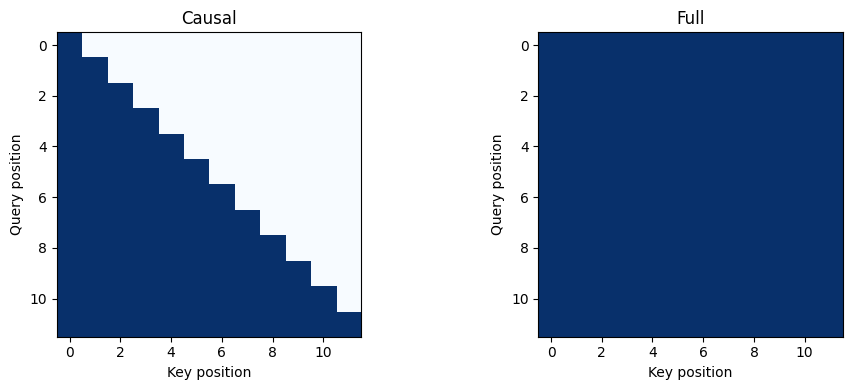

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, causal, name in zip(axs, (True, False), ('Causal', 'Full')):
    ax.imshow(attention_visibility(12, causal), cmap='Blues', vmin=0, vmax=1)
    ax.set(title=name, xlabel='Key position', ylabel='Query position')
plt.tight_layout()
plt.show()

## 2. Reported outcomes (3 seeds × 3 tasks × 2 modes)

Every result below can be audited against **2,000 test labels and predictions per run** in the included `runs.json`. Numbers here are observed on a carefully constructed, IID synthetic distribution.

 left | causal: 100.00% ± 0.00%
 left |   full: 100.00% ± 0.00%
right | causal: 49.25% ± 0.31%
right |   full: 100.00% ± 0.00%
  xor | causal: 49.55% ± 1.10%
  xor |   full: 100.00% ± 0.00%


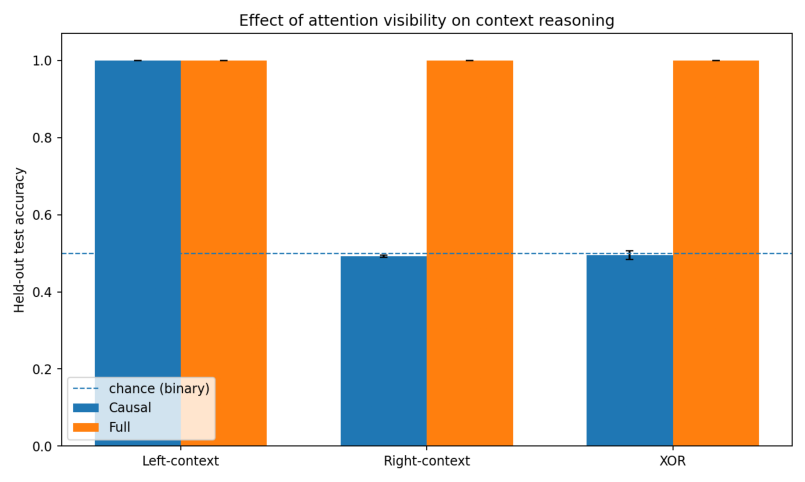

In [3]:
aggregate = json.loads((ROOT / 'results/benchmark_3seeds/aggregate.json').read_text())
for row in aggregate['aggregate']:
    print(f"{row['task']:>5} | {row['mode']:>6}: {row['mean_accuracy']:.2%} ± {row['sample_std_accuracy']:.2%}")
image = plt.imread(ROOT / 'assets/test_accuracy.png')
plt.figure(figsize=(11, 6))
plt.imshow(image)
plt.axis('off')
plt.show()

## 3. Inspect two *real trained checkpoints* on the same input

Use identical input tokens and query positions. Change only the attention mask by selecting the corresponding trained checkpoint. The labels depend on **both** left and right bits (XOR).

In [4]:
data = make_dataset(1, 'xor', seed=2026)
print('Input:', token_description(data.tokens[0]))
print('Query position:', int(data.query_positions[0]))
print('True label:', int(data.targets[0]))

models = {}
for mode in ['causal', 'full']:
    state = torch.load(ROOT / f'models/xor_{mode}_seed7.pt', map_location='cpu', weights_only=True)
    model = ContextTransformer(ModelConfig(**state['architecture']), mode).eval()
    model.load_state_dict(state['model'])
    models[mode] = model
    with torch.no_grad():
        logits, weights = model(data.tokens, data.query_positions, inspect=True)
    print(f'{mode:>6}: p(class=1)={logits.softmax(-1)[0,1].item():.4f}, predicted={logits.argmax(-1).item()}')

Input: ['noise:14', 'LEFT:1', 'noise:12', '<QUERY>', 'noise:12', 'RIGHT:0', 'noise:20', 'noise:18', 'noise:22', 'noise:18', 'noise:9', 'noise:21']
Query position: 3
True label: 1
causal: p(class=1)=0.4388, predicted=0
  full: p(class=1)=0.9991, predicted=1


## 4. A direct **future-token leakage test**

Replace every token strictly **after** the query; compare logits. A truly causal readout must be invariant (within floating point tolerance). Unrestricted attention *may* change — that is expected, and does not by itself prove which features caused the prediction.

In [5]:
changed = data.tokens.clone()
q = int(data.query_positions[0])
changed[0, q+1:] = 6
for mode, model in models.items():
    with torch.no_grad():
        before = model(data.tokens, data.query_positions)
        after = model(changed, data.query_positions)
    print(f'{mode:>6} maximum absolute logit change: {(before-after).abs().max().item():.8f}')

causal maximum absolute logit change: 0.00000000
  full maximum absolute logit change: 7.12728119


## 5. Look at the query's attention distribution

Attention visualizations are **diagnostic**, not a faithful explanation of model causality. They show which positions were available and how attention probability was distributed for the *trained* model.

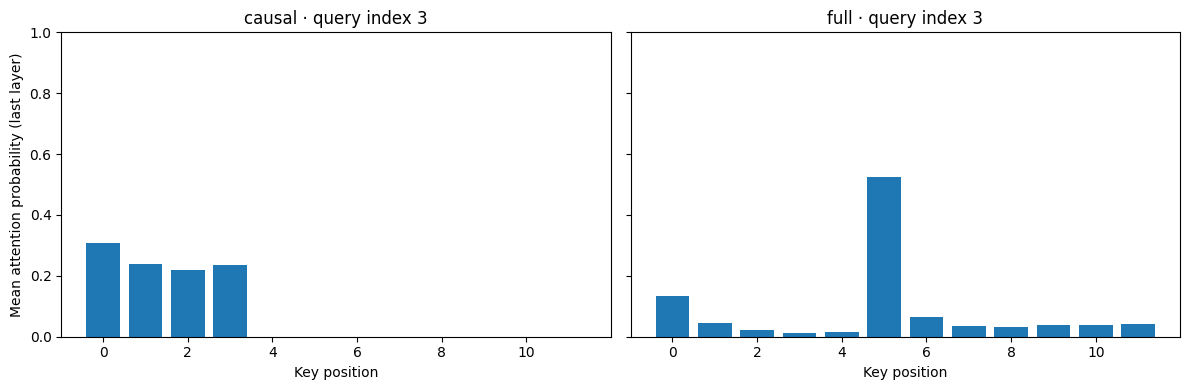

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (mode, model) in zip(axs, models.items()):
    with torch.no_grad():
        _, weights = model(data.tokens, data.query_positions, inspect=True)
    query_weights = weights[-1][0, :, q, :].mean(0).cpu().numpy()
    ax.bar(range(len(query_weights)), query_weights)
    ax.set(title=f'{mode} · query index {q}', xlabel='Key position', ylim=(0, 1))
axs[0].set_ylabel('Mean attention probability (last layer)')
plt.tight_layout()
plt.show()

## Takeaway

This experimental design isolates *access to future context*. It is intentionally easy for full attention and information-theoretically restricted for causal attention. **Do not** extrapolate synthetic 100% accuracy to natural language or production systems. Further experiments on realistic token-level datasets with controlled prediction objectives are needed.

[See the methodology](../docs/METHODOLOGY.md) · [See the model card](../docs/MODEL_CARD.md)